# Neural Network-Based Taxi Trip Prediction Using Big Data Processing with PySpark

## MSc Data Analytics – Integrated CA1

Dataset: Yellow Taxi Trip Data 2017

In [ ]:
!pip install -q pyspark

In [2]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pyspark.sql import SparkSession
from pyspark.sql.functions import *

In [3]:
#Start Spark

spark = SparkSession.builder \
    .appName("TaxiTripNeuralNetwork") \
    .getOrCreate()

print("Spark version:", spark.version)

Spark version: 4.0.4


In [4]:
import os

print(os.listdir())

['.config', 'C2_2017_Yellow_Taxi_Trip_Data.csv', 'sample_data']


In [5]:
#Load the dataset using PySpark


file_path = "/content/C2_2017_Yellow_Taxi_Trip_Data.csv"

taxi_df = spark.read.csv(
    file_path,
    header=True,
    inferSchema=True
)

print("Dataset loaded successfully")

Dataset loaded successfully


In [6]:
#Check the number of rows and columns


print("Number of rows:", taxi_df.count())
print("Number of columns:", len(taxi_df.columns))

print(taxi_df.columns)

Number of rows: 22699
Number of columns: 18
['_c0', 'VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount']


In [7]:
#View the first records

taxi_df.show(10, truncate=False)

+---------+--------+----------------------+----------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+
|_c0      |VendorID|tpep_pickup_datetime  |tpep_dropoff_datetime |passenger_count|trip_distance|RatecodeID|store_and_fwd_flag|PULocationID|DOLocationID|payment_type|fare_amount|extra|mta_tax|tip_amount|tolls_amount|improvement_surcharge|total_amount|
+---------+--------+----------------------+----------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+
|24870114 |2       |03/25/2017 8:55:43 AM |03/25/2017 9:09:47 AM |6              |3.34         |1         |N                 |100         |231         |1           |13.0       |0.0  |0.5    |2.76      |0.0         |0.3                  |16.56     

In [8]:
#Check the data types

taxi_df.printSchema()

root
 |-- _c0: integer (nullable = true)
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: string (nullable = true)
 |-- tpep_dropoff_datetime: string (nullable = true)
 |-- passenger_count: integer (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- RatecodeID: integer (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- payment_type: integer (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)



In [9]:
#Check missing values

missing_values = taxi_df.select([
    count(when(col(c).isNull(), c)).alias(c)
    for c in taxi_df.columns
])

missing_values.show()

+---+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+
|_c0|VendorID|tpep_pickup_datetime|tpep_dropoff_datetime|passenger_count|trip_distance|RatecodeID|store_and_fwd_flag|PULocationID|DOLocationID|payment_type|fare_amount|extra|mta_tax|tip_amount|tolls_amount|improvement_surcharge|total_amount|
+---+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+
|  0|       0|                   0|                    0|              0|            0|         0|                 0|           0|           0|           0|          0|    0|      0|         0|           0|                    0|           0|
+---+--------+------------------

In [10]:
#Basic statistics

taxi_df.describe().show()

+-------+--------------------+------------------+--------------------+---------------------+------------------+------------------+------------------+------------------+------------------+------------------+-------------------+------------------+-------------------+-------------------+------------------+------------------+---------------------+------------------+
|summary|                 _c0|          VendorID|tpep_pickup_datetime|tpep_dropoff_datetime|   passenger_count|     trip_distance|        RatecodeID|store_and_fwd_flag|      PULocationID|      DOLocationID|       payment_type|       fare_amount|              extra|            mta_tax|        tip_amount|      tolls_amount|improvement_surcharge|      total_amount|
+-------+--------------------+------------------+--------------------+---------------------+------------------+------------------+------------------+------------------+------------------+------------------+-------------------+------------------+-------------------+-----

In [11]:
#Check duplicate rows

print("Total rows:", taxi_df.count())

print("Distinct rows:", taxi_df.dropDuplicates().count())

Total rows: 22699
Distinct rows: 22699


In [12]:
#Remove the unnecessary _c0 column

taxi_df = taxi_df.drop("_c0")

print(taxi_df.columns)

['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount']


In [13]:
#Convert pickup and drop-off time

taxi_df = taxi_df.withColumn(
    "pickup_datetime",
    to_timestamp("tpep_pickup_datetime")
)

taxi_df = taxi_df.withColumn(
    "dropoff_datetime",
    to_timestamp("tpep_dropoff_datetime")
)


taxi_df.printSchema()

root
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: string (nullable = true)
 |-- tpep_dropoff_datetime: string (nullable = true)
 |-- passenger_count: integer (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- RatecodeID: integer (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- payment_type: integer (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- pickup_datetime: timestamp (nullable = true)
 |-- dropoff_datetime: timestamp (nullable = true)



In [14]:
#Create useful time features

# Re-convert pickup and drop-off time with explicit format to ensure correct parsing
taxi_df = taxi_df.withColumn(
    "pickup_datetime",
    to_timestamp("tpep_pickup_datetime", "MM/dd/yyyy h:mm:ss a")
)

taxi_df = taxi_df.withColumn(
    "dropoff_datetime",
    to_timestamp("tpep_dropoff_datetime", "MM/dd/yyyy h:mm:ss a")
)

taxi_df = taxi_df.withColumn(
    "pickup_hour",
    hour("pickup_datetime")
)

taxi_df = taxi_df.withColumn(
    "pickup_day",
    dayofweek("pickup_datetime")
)

taxi_df = taxi_df.withColumn(
    "pickup_month",
    month("pickup_datetime")
)



taxi_df.select(
    "pickup_datetime",
    "pickup_hour",
    "pickup_day",
    "pickup_month"
).show(10)

+-------------------+-----------+----------+------------+
|    pickup_datetime|pickup_hour|pickup_day|pickup_month|
+-------------------+-----------+----------+------------+
|2017-03-25 08:55:43|          8|         7|           3|
|2017-04-11 14:53:28|         14|         3|           4|
|2017-12-15 07:26:56|          7|         6|          12|
|2017-05-07 13:17:59|         13|         1|           5|
|2017-04-15 23:32:20|         23|         7|           4|
|2017-03-25 20:34:11|         20|         7|           3|
|2017-05-03 19:04:09|         19|         4|           5|
|2017-08-15 17:41:06|         17|         3|           8|
|2017-02-04 16:17:07|         16|         7|           2|
|2017-11-10 15:20:29|         15|         6|          11|
+-------------------+-----------+----------+------------+
only showing top 10 rows


In [15]:
#Create our target variable


taxi_df = taxi_df.withColumn(
    "trip_duration_minutes",
    (
        unix_timestamp("dropoff_datetime") -
        unix_timestamp("pickup_datetime")
    ) / 60
)


taxi_df.select(
    "pickup_datetime",
    "dropoff_datetime",
    "trip_duration_minutes"
).show(10)

+-------------------+-------------------+---------------------+
|    pickup_datetime|   dropoff_datetime|trip_duration_minutes|
+-------------------+-------------------+---------------------+
|2017-03-25 08:55:43|2017-03-25 09:09:47|   14.066666666666666|
|2017-04-11 14:53:28|2017-04-11 15:19:58|                 26.5|
|2017-12-15 07:26:56|2017-12-15 07:34:08|                  7.2|
|2017-05-07 13:17:59|2017-05-07 13:48:14|                30.25|
|2017-04-15 23:32:20|2017-04-15 23:49:03|   16.716666666666665|
|2017-03-25 20:34:11|2017-03-25 20:42:11|                  8.0|
|2017-05-03 19:04:09|2017-05-03 20:03:47|    59.63333333333333|
|2017-08-15 17:41:06|2017-08-15 18:03:05|   21.983333333333334|
|2017-02-04 16:17:07|2017-02-04 16:29:14|   12.116666666666667|
|2017-11-10 15:20:29|2017-11-10 15:40:55|   20.433333333333334|
+-------------------+-------------------+---------------------+
only showing top 10 rows


In [16]:
#Check trip-duration values


taxi_df.select(
    "trip_duration_minutes"
).describe().show()


taxi_df.select(
    "trip_duration_minutes"
).orderBy(
    "trip_duration_minutes"
).show(10)



taxi_df.select(
    "trip_duration_minutes"
).orderBy(
    col("trip_duration_minutes").desc()
).show(10)

+-------+---------------------+
|summary|trip_duration_minutes|
+-------+---------------------+
|  count|                22699|
|   mean|   17.013776671512638|
| stddev|   61.996482055110334|
|    min|  -16.983333333333334|
|    max|              1439.55|
+-------+---------------------+

+---------------------+
|trip_duration_minutes|
+---------------------+
|  -16.983333333333334|
|                  0.0|
|                  0.0|
|                  0.0|
|                  0.0|
|                  0.0|
|                  0.0|
|                  0.0|
|                  0.0|
|                  0.0|
+---------------------+
only showing top 10 rows
+---------------------+
|trip_duration_minutes|
+---------------------+
|              1439.55|
|              1439.15|
|              1438.85|
|              1438.65|
|              1438.55|
|   1438.4666666666667|
|   1438.2666666666667|
|   1438.0333333333333|
|   1437.8333333333333|
|   1436.9666666666667|
+---------------------+
only showing t

In [17]:
#Clean trip duration

taxi_clean = taxi_df.filter(
    (col("trip_duration_minutes") >= 1) &
    (col("trip_duration_minutes") <= 180)
)

print("Rows before cleaning:", taxi_df.count())
print("Rows after cleaning:", taxi_clean.count())

Rows before cleaning: 22699
Rows after cleaning: 22438


In [18]:
#Check the cleaned data


taxi_clean.select(
    "trip_duration_minutes"
).describe().show()

+-------+---------------------+
|summary|trip_duration_minutes|
+-------+---------------------+
|  count|                22438|
|   mean|   14.460239326143032|
| stddev|   11.579937979214249|
|    min|                  1.0|
|    max|   159.31666666666666|
+-------+---------------------+



In [19]:
#Check important numerical variables


taxi_clean.select(
    "passenger_count",
    "trip_distance",
    "fare_amount",
    "tip_amount",
    "tolls_amount",
    "total_amount",
    "trip_duration_minutes"
).describe().show()

+-------+------------------+-----------------+------------------+------------------+-------------------+------------------+---------------------+
|summary|   passenger_count|    trip_distance|       fare_amount|        tip_amount|       tolls_amount|      total_amount|trip_duration_minutes|
+-------+------------------+-----------------+------------------+------------------+-------------------+------------------+---------------------+
|  count|             22438|            22438|             22438|             22438|              22438|             22438|                22438|
|   mean|1.6439967911578572|2.934105980925235|12.905683215972905|1.8207598716463065|0.30916659238791877|16.171680185396358|   14.460239326143032|
| stddev|1.2864162619221908|3.653527233750876| 10.72749958867724| 2.416558313445634|   1.38571697835945|13.307071255065711|   11.579937979214249|
|    min|                 0|              0.0|              -4.5|               0.0|                0.0|              -5.8| 

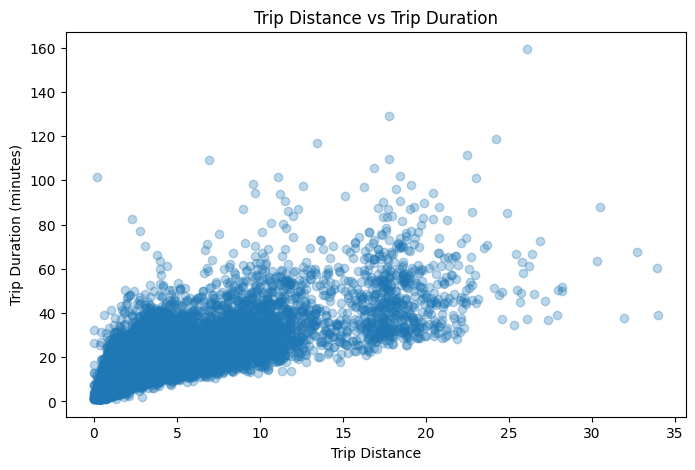

In [20]:
#Create a simple graph


plot_df = taxi_clean.select(
    "trip_distance",
    "trip_duration_minutes"
).toPandas()

plt.figure(figsize=(8,5))
plt.scatter(
    plot_df["trip_distance"],
    plot_df["trip_duration_minutes"],
    alpha=0.3
)

plt.xlabel("Trip Distance")
plt.ylabel("Trip Duration (minutes)")
plt.title("Trip Distance vs Trip Duration")
plt.show()

In [21]:
#Select the features
feature_columns = [
    "passenger_count",
    "trip_distance",
    "RatecodeID",
    "PULocationID",
    "DOLocationID",
    "pickup_hour",
    "pickup_day",
    "pickup_month"
]

target_column = "trip_duration_minutes"

model_df = taxi_clean.select(
    feature_columns + [target_column]
)

model_df.show(10)

+---------------+-------------+----------+------------+------------+-----------+----------+------------+---------------------+
|passenger_count|trip_distance|RatecodeID|PULocationID|DOLocationID|pickup_hour|pickup_day|pickup_month|trip_duration_minutes|
+---------------+-------------+----------+------------+------------+-----------+----------+------------+---------------------+
|              6|         3.34|         1|         100|         231|          8|         7|           3|   14.066666666666666|
|              1|          1.8|         1|         186|          43|         14|         3|           4|                 26.5|
|              1|          1.0|         1|         262|         236|          7|         6|          12|                  7.2|
|              1|          3.7|         1|         188|          97|         13|         1|           5|                30.25|
|              1|         4.37|         1|           4|         112|         23|         7|           4|   16.7

In [22]:
#Check for any remaining invalid values


model_df.describe().show()

model_df.select([
    sum(when(col(c).isNull(), 1).otherwise(0)).alias(c)
    for c in model_df.columns
]).show()

+-------+------------------+-----------------+-------------------+------------------+------------------+------------------+-----------------+-----------------+---------------------+
|summary|   passenger_count|    trip_distance|         RatecodeID|      PULocationID|      DOLocationID|       pickup_hour|       pickup_day|     pickup_month|trip_duration_minutes|
+-------+------------------+-----------------+-------------------+------------------+------------------+------------------+-----------------+-----------------+---------------------+
|  count|             22438|            22438|              22438|             22438|             22438|             22438|            22438|            22438|                22438|
|   mean|1.6439967911578572|2.934105980925235|  1.031375345396203|162.27957037169088|161.46029057848293| 13.72649077457884|4.102415545057492|6.422631250557091|   14.460239326143032|
| stddev|1.2864162619221908|3.653527233750876|0.22873642658653337| 66.59640877864439| 70.0

In [23]:
#Create the feature vector


from pyspark.ml.feature import VectorAssembler

assembler = VectorAssembler(
    inputCols=feature_columns,
    outputCol="features"
)

assembled_df = assembler.transform(model_df)

assembled_df.select(
    "features",
    "trip_duration_minutes"
).show(5, truncate=False)

+--------------------------------------+---------------------+
|features                              |trip_duration_minutes|
+--------------------------------------+---------------------+
|[6.0,3.34,1.0,100.0,231.0,8.0,7.0,3.0]|14.066666666666666   |
|[1.0,1.8,1.0,186.0,43.0,14.0,3.0,4.0] |26.5                 |
|[1.0,1.0,1.0,262.0,236.0,7.0,6.0,12.0]|7.2                  |
|[1.0,3.7,1.0,188.0,97.0,13.0,1.0,5.0] |30.25                |
|[1.0,4.37,1.0,4.0,112.0,23.0,7.0,4.0] |16.716666666666665   |
+--------------------------------------+---------------------+
only showing top 5 rows


In [31]:
train_df, test_df = assembled_df.randomSplit(
    [0.8, 0.2],
    seed=42
)

print("Training rows:", train_df.count())
print("Testing rows:", test_df.count())

Training rows: 18005
Testing rows: 4433


In [33]:
#Convert Spark data to NumPy

train_pd = train_df.toPandas()
test_pd = test_df.toPandas()

X_train = np.array(
    train_pd["features"].tolist()
)

y_train = train_pd["trip_duration_minutes"].values

X_test = np.array(
    test_pd["features"].tolist()
)

y_test = test_pd["trip_duration_minutes"].values

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (18005, 8)
y_train: (18005,)
X_test: (4433, 8)
y_test: (4433,)


In [34]:
#Scale the features


from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling completed.")

Scaling completed.


In [35]:
#Check the final data


print("Training data:", X_train_scaled.shape)
print("Testing data:", X_test_scaled.shape)
print("Number of input features:", X_train_scaled.shape[1])

Training data: (18005, 8)
Testing data: (4433, 8)
Number of input features: 8


#Model 1

In [36]:
#Build Neural Network Model 1


import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


In [37]:
#Create Model 1


model_1 = keras.Sequential([
    layers.Input(shape=(8,)),
    layers.Dense(16, activation="relu"),
    layers.Dense(1)
])

model_1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 161 (644.00 B)

 Trainable params: 161 (644.00 B)

 Non-trainable params: 0 (0.00 B)

In [38]:
#Compile Model 1

model_1.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

In [39]:
#Train Model 1

history_1 = model_1.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=32,
    verbose=1
)

Epoch 1/20
451/451 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 217.9587 - mae: 10.5870 - val_loss: 287.7547 - val_mae: 12.9394
Epoch 2/20
451/451 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 81.5572 - mae: 6.0884 - val_loss: 199.0718 - val_mae: 10.5702
Epoch 3/20
451/451 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 54.6204 - mae: 5.2488 - val_loss: 185.5206 - val_mae: 10.3910
Epoch 4/20
451/451 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 49.5776 - mae: 4.9214 - val_loss: 174.3143 - val_mae: 10.0484
Epoch 5/20
451/451 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 46.9235 - mae: 4.7307 - val_loss: 162.4532 - val_mae: 9.5855
Epoch 6/20
451/451 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 44.8313 - mae: 4.5501 - val_loss: 149.5002 - val_mae: 8.9827
Epoch 7/20
451/451 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 42.8704 - mae: 4.3827 - val_loss: 134.8732 - val_mae: 8.3117
Epoch 8/20
451/451 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 41.2235 - mae: 4.2493 - val_loss: 122.7563 - val_mae: 7.7198
Epoch 9/20
451/451 ━━━━━━━

In [40]:
#Evaluate Model 1

test_loss_1, test_mae_1 = model_1.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

print("Model 1 Test Loss (MSE):", test_loss_1)
print("Model 1 Test MAE:", test_mae_1)

Model 1 Test Loss (MSE): 47.558353424072266
Model 1 Test MAE: 4.407211780548096


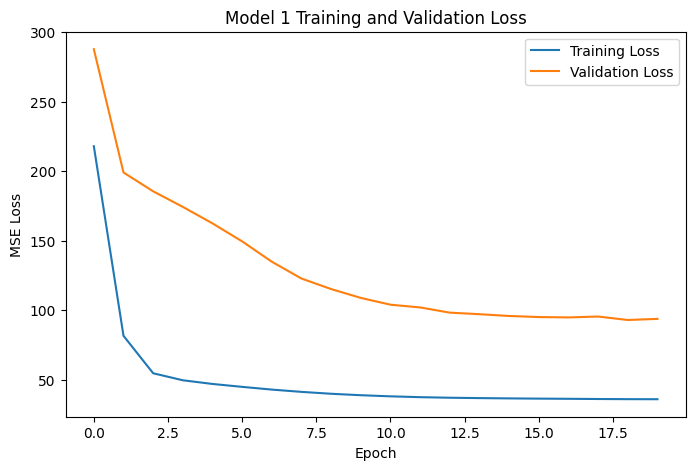

In [41]:
#Plot Model 1 training

plt.figure(figsize=(8,5))

plt.plot(history_1.history["loss"], label="Training Loss")
plt.plot(history_1.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Model 1 Training and Validation Loss")
plt.legend()
plt.show()

#Model 2

In [42]:
#Build Model 2: Improved Neural Network
#Create Model 2

model_2 = keras.Sequential([
    layers.Input(shape=(8,)),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(1)
])

model_2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 32)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 833 (3.25 KB)

 Trainable params: 833 (3.25 KB)

 Non-trainable params: 0 (0.00 B)

In [43]:
#Compile Model 2

model_2.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

In [44]:
#Train Model 2

history_2 = model_2.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=32,
    verbose=1
)

Epoch 1/20
451/451 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 117.7519 - mae: 7.3319 - val_loss: 149.3513 - val_mae: 8.6686
Epoch 2/20
451/451 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 49.8394 - mae: 4.8801 - val_loss: 133.7377 - val_mae: 8.2594
Epoch 3/20
451/451 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 43.9972 - mae: 4.4590 - val_loss: 100.2786 - val_mae: 6.5851
Epoch 4/20
451/451 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 40.1314 - mae: 4.1749 - val_loss: 86.7656 - val_mae: 6.0816
Epoch 5/20
451/451 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 37.9564 - mae: 4.0143 - val_loss: 84.9751 - val_mae: 6.0833
Epoch 6/20
451/451 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 36.6725 - mae: 3.9282 - val_loss: 84.2117 - val_mae: 6.1228
Epoch 7/20
451/451 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 35.9708 - mae: 3.8830 - val_loss: 81.8324 - val_mae: 6.1212
Epoch 8/20
451/451 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 35.4731 - mae: 3.8645 - val_loss: 83.1307 - val_mae: 6.1934
Epoch 9/20
451/451 ━━━━━━━━━━━━━━━━━

In [45]:
#Evaluate Model 2

test_loss_2, test_mae_2 = model_2.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

print("Model 2 Test Loss (MSE):", test_loss_2)
print("Model 2 Test MAE:", test_mae_2)

Model 2 Test Loss (MSE): 41.717079162597656
Model 2 Test MAE: 4.286358833312988


In [46]:
#Compare Model 1 and Model 2


comparison = pd.DataFrame({
    "Model": [
        "Model 1 - Basic",
        "Model 2 - Improved"
    ],
    "MSE": [
        test_loss_1,
        test_loss_2
    ],
    "MAE": [
        test_mae_1,
        test_mae_2
    ]
})

comparison

,Model,MSE,MAE
0,Model 1 - Basic,47.558353,4.407212
1,Model 2 - Improved,41.717079,4.286359


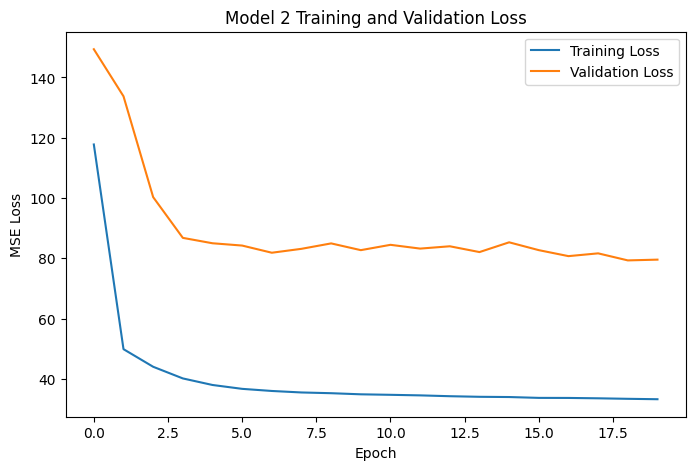

In [47]:
#Plot Model 2 training

plt.figure(figsize=(8,5))

plt.plot(
    history_2.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_2.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Model 2 Training and Validation Loss")
plt.legend()
plt.show()

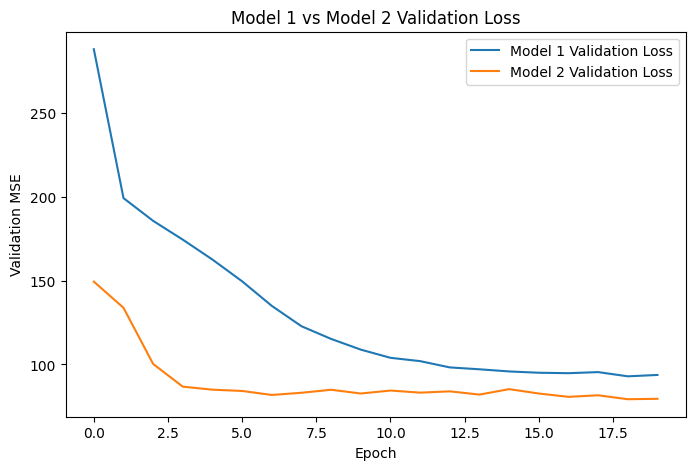

In [48]:
#Compare the training curves


plt.figure(figsize=(8,5))

plt.plot(
    history_1.history["val_loss"],
    label="Model 1 Validation Loss"
)

plt.plot(
    history_2.history["val_loss"],
    label="Model 2 Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Validation MSE")
plt.title("Model 1 vs Model 2 Validation Loss")
plt.legend()
plt.show()

#Model 3

In [49]:
#Build Model 3
model_3 = keras.Sequential([
    layers.Input(shape=(8,)),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(16, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(1)
])

model_3.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 32)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 833 (3.25 KB)

 Trainable params: 833 (3.25 KB)

 Non-trainable params: 0 (0.00 B)

In [50]:
#Compile Model 3

model_3.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

In [51]:
#Add Early Stopping

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

In [52]:
#Train Model 3

history_3 = model_3.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/50
451/451 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 153.2134 - mae: 8.4093 - val_loss: 160.3362 - val_mae: 8.7586
Epoch 2/50
451/451 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 67.1441 - mae: 5.6866 - val_loss: 140.1255 - val_mae: 8.3431
Epoch 3/50
451/451 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 64.8928 - mae: 5.4132 - val_loss: 133.0069 - val_mae: 7.9599
Epoch 4/50
451/451 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 59.7078 - mae: 5.2044 - val_loss: 118.2734 - val_mae: 7.3262
Epoch 5/50
451/451 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 57.6265 - mae: 5.0696 - val_loss: 107.5484 - val_mae: 6.8460
Epoch 6/50
451/451 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 57.8907 - mae: 5.0187 - val_loss: 100.1807 - val_mae: 6.5439
Epoch 7/50
451/451 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 55.8350 - mae: 4.9246 - val_loss: 89.8401 - val_mae: 6.1667
Epoch 8/50
451/451 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 54.4456 - mae: 4.8481 - val_loss: 86.3919 - val_mae: 6.0364
Epoch 9/50
451/451 ━━━━━━━━━━━━━━

In [53]:
#Evaluate Model 3

test_loss_3, test_mae_3 = model_3.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

print("Model 3 Test Loss (MSE):", test_loss_3)
print("Model 3 Test MAE:", test_mae_3)

Model 3 Test Loss (MSE): 40.60801315307617
Model 3 Test MAE: 4.233762264251709


In [54]:
#Compare all 3 models


comparison = pd.DataFrame({
    "Model": [
        "Model 1 - Basic",
        "Model 2 - Improved",
        "Model 3 - Final"
    ],
    "MSE": [
        test_loss_1,
        test_loss_2,
        test_loss_3
    ],
    "MAE": [
        test_mae_1,
        test_mae_2,
        test_mae_3
    ]
})

comparison

,Model,MSE,MAE
0,Model 1 - Basic,47.558353,4.407212
1,Model 2 - Improved,41.717079,4.286359
2,Model 3 - Final,40.608013,4.233762


In [55]:
#Find the best model


best_model = comparison.loc[
    comparison["MAE"].idxmin()
]

print("Best Model:", best_model["Model"])
print("Best MAE:", best_model["MAE"])
print("Best MSE:", best_model["MSE"])

Best Model: Model 3 - Final
Best MAE: 4.233762264251709
Best MSE: 40.60801315307617


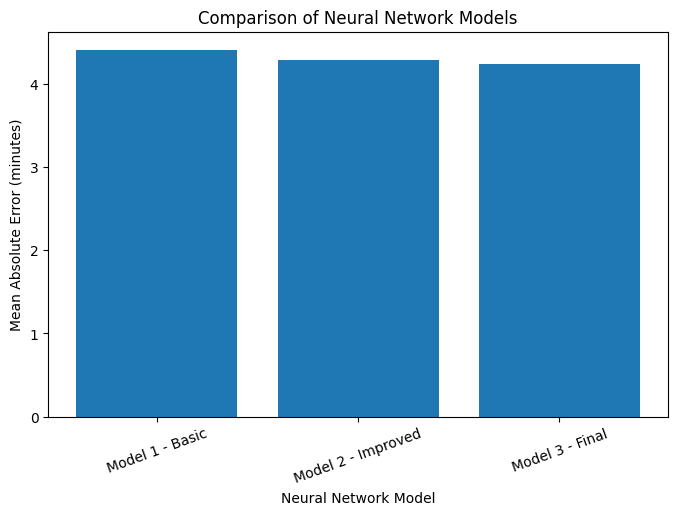

In [56]:
#Plot all model performance


plt.figure(figsize=(8,5))

plt.bar(
    comparison["Model"],
    comparison["MAE"]
)

plt.ylabel("Mean Absolute Error (minutes)")
plt.xlabel("Neural Network Model")
plt.title("Comparison of Neural Network Models")
plt.xticks(rotation=20)
plt.show()

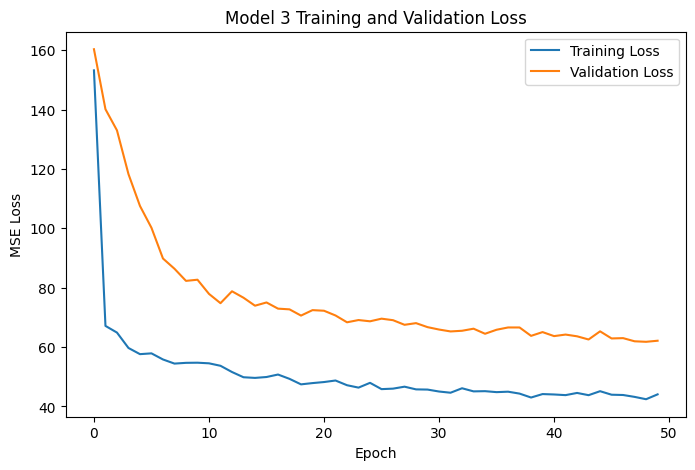

In [57]:
#Plot Model 3 training


plt.figure(figsize=(8,5))

plt.plot(
    history_3.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_3.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Model 3 Training and Validation Loss")
plt.legend()
plt.show()

In [58]:
#Make predictions


predictions = model_3.predict(
    X_test_scaled
).flatten()

results = pd.DataFrame({
    "Actual Duration": y_test,
    "Predicted Duration": predictions
})

results.head(10)

139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


,Actual Duration,Predicted Duration
0,6.900000,7.070133
1,13.600000,9.661547
2,10.300000,10.579618
3,5.566667,9.161249
4,15.650000,12.389185
5,23.616667,18.482611
6,21.616667,29.828485
7,1.083333,4.676710
8,1.516667,4.370748
9,1.283333,2.788312


In [60]:
#Calculate prediction errors


results["Error"] = (
    results["Actual Duration"] -
    results["Predicted Duration"]
)

results["Absolute Error"] = np.abs(results["Error"])

results.head(10)

,Actual Duration,Predicted Duration,Error,Absolute Error
0,6.900000,7.070133,-0.170133,0.170133
1,13.600000,9.661547,3.938453,3.938453
2,10.300000,10.579618,-0.279618,0.279618
3,5.566667,9.161249,-3.594582,3.594582
4,15.650000,12.389185,3.260815,3.260815
5,23.616667,18.482611,5.134056,5.134056
6,21.616667,29.828485,-8.211819,8.211819
7,1.083333,4.676710,-3.593377,3.593377
8,1.516667,4.370748,-2.854081,2.854081
9,1.283333,2.788312,-1.504979,1.504979


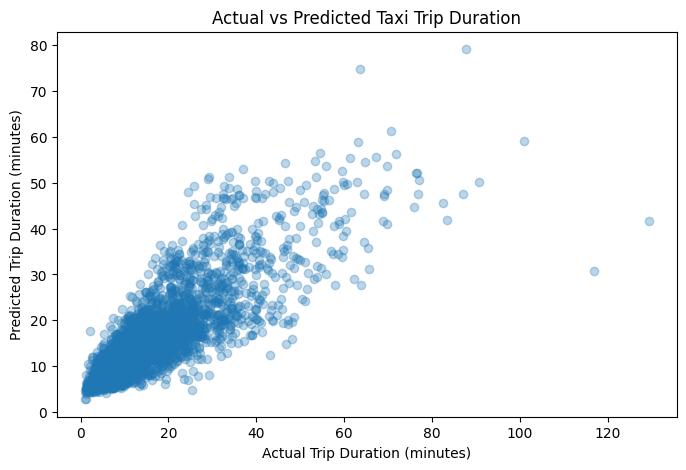

In [61]:
#Create Actual vs Predicted graph


plt.figure(figsize=(8,5))

plt.scatter(
    results["Actual Duration"],
    results["Predicted Duration"],
    alpha=0.3
)

plt.xlabel("Actual Trip Duration (minutes)")
plt.ylabel("Predicted Trip Duration (minutes)")
plt.title("Actual vs Predicted Taxi Trip Duration")

plt.show()

In [63]:
#Calculate R²


from sklearn.metrics import r2_score

r2 = r2_score(
    y_test,
    predictions
)

print("R² Score:", r2)

R² Score: 0.6954259044563712


In [65]:
#Create the final results table


from sklearn.metrics import mean_squared_error, mean_absolute_error

final_mse = mean_squared_error(
    y_test,
    predictions
)

final_mae = mean_absolute_error(
    y_test,
    predictions
)

final_results = pd.DataFrame({
    "Metric": ["MSE", "MAE", "R²"],
    "Value": [final_mse, final_mae, r2]
})

final_results

,Metric,Value
0,MSE,40.608015
1,MAE,4.233762
2,R²,0.695426
